# Coronagraphs: imaging a planet next to its star

Seen from 10 parsecs, the Earth is a speck 0.1 arcseconds from the Sun and
ten billion times fainter. A 6 m telescope in space resolves that
separation easily: at 550 nm its diffraction limit $\lambda/D$ is 19
milliarcseconds, so the Earth sits about 5 $\lambda/D$ from the Sun. The
problem is not resolution but contrast. The Airy pattern of the Sun is
still a million times brighter than the Earth at that distance, and the
rings fall below $10^{-10}$ only some 700 $\lambda/D$ out.

A coronagraph removes the light of the star before it reaches the camera
and lets the light of anything beside it through. Bernard Lyot built the
first one in 1930 to see the solar corona without an eclipse: an
occulting disk in the focal plane, and a stop in the image of the pupil
that blocks the light the disk diffracts. Modern stellar coronagraphs
keep his four planes (pupil, focal plane mask, Lyot stop, camera) and
change what sits in them.

This notebook covers:

1. how faint planets are, and the diffraction pattern of a clear and of
   an obscured telescope pupil against $10^{-10}$,
2. apodized pupils: softening the edge of the pupil (Sonine and prolate
   apodizations) against the analytic PSFs, and what that costs,
3. the Lyot coronagraph: where the light goes in the Lyot plane (exactly
   $J_0(\pi a)$ at the centre of the pupil), contrast against the size of
   the Lyot stop, and the planet throughput,
4. the apodized pupil Lyot coronagraph, whose prolate apodizer makes the
   field behind the mask exactly $(1-\Lambda)$ times itself,
5. the vortex coronagraph of charge 2, 4 and 6: the light sent outside
   the pupil (against the analytic Lyot plane fields), the inner working
   angle and why a central obscuration spoils it,
6. sensitivity to pointing and low order aberrations: the $\alpha^2$ and
   $\alpha^4$ leaks of the vortex and its Zernike selection rule, and
   contrast curves with pointing jitter,
7. a dark hole: a deformable mirror and electric field conjugation take
   the speckles of nanometre aberrations down by three orders of
   magnitude, and a planet of $10^{-10}$ emerges.

Notebook 72 covers the turbulent atmosphere and adaptive optics, notebook
69 optical vortices and notebook 74 stellar interferometry. Here the
telescope is in space: the wavefront is static and nearly perfect, and
everything is monochromatic and scalar.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.special import gamma, j0, j1
from scipy.optimize import brentq

from pyoptics import coronagraph as cg
from pyoptics import sketch
from pyoptics.bases import fringe_zernike, fringe_to_n_m

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

# pupil plane: 256 samples across the diameter D, on a grid 1.25 D wide (units of D)
x = cg.pupil_grid(320, 1.25)
dA = (x[1] - x[0])**2
X, Y = np.meshgrid(x, x)
R = np.hypot(X, Y)
P = cg.telescope_pupil(x, x, oversample=16)       # clear circular pupil, antialiased edge

## 1. How faint is a planet?

A planet of radius $R_p$ at a distance $a$ from its star reflects the
fraction

$$C = A_g\,\Phi(\beta)\left(\frac{R_p}{a}\right)^2$$

of the star's flux, with the geometric albedo $A_g$ and the phase function
$\Phi$ ($1/\pi$ at quadrature for a Lambert sphere, Traub and Oppenheimer
2010). At a distance $d$ its largest separation is $a/d$.

In [2]:
AU, pc, R_E, R_J = 1.496e11, 3.086e16, 6.371e6, 7.149e7
mas = np.pi/180/3600e3
planets = {"Earth": (0.367, R_E, 1.0*AU), "Jupiter": (0.52, R_J, 5.2*AU)}
d = 10*pc
lod = {"6 m, 550 nm": 550e-9/6.0, "8 m, 1.6 µm": 1.6e-6/8.0}     # lambda/D in rad
print("                 contrast    separation   " + "   ".join("{:>14s}".format(k) for k in lod))
contrasts = {}
for name, (Ag, Rp, a) in planets.items():
    C = Ag/np.pi*(Rp/a)**2
    contrasts[name] = (C, a/d)
    print("{:8s}       {:9.2e}    {:6.0f} mas   ".format(name, C, a/d/mas)
          + "   ".join("{:9.1f} λ/D   ".format(a/d/v) for v in lod.values()))
print("\nlambda/D: " + ", ".join("{} = {:.1f} mas".format(k, v/mas) for k, v in lod.items()))

                 contrast    separation      6 m, 550 nm      8 m, 1.6 µm
Earth           2.12e-10       100 mas         5.3 λ/D            2.4 λ/D   
Jupiter         1.40e-09       520 mas        27.5 λ/D           12.6 λ/D   

lambda/D: 6 m, 550 nm = 18.9 mas, 8 m, 1.6 µm = 41.3 mas


An Earth twin is $2\times10^{-10}$ of its star, a Jupiter twin $1.4\times10^{-9}$,
at 5 and 27 $\lambda/D$ for a 6 m telescope in the visible. Young, self
luminous giant planets in the infrared are $10^{-5}$ to $10^{-6}$; they are
what ground based coronagraphs with adaptive optics image today.

The telescope alone forms the Fraunhofer pattern of its pupil. With pupil
coordinates $x$ in units of $D$ and focal plane coordinates $u$ in units
of $\lambda/D$, the field in the focal plane is

$$E(u,v) = \iint P(x,y)\,e^{-2\pi i (ux + vy)}\,dx\,dy,$$

which the matrix Fourier transform evaluates on any grid (`cg.mft()`,
Soummer et al. 2007). A clear circular pupil gives the Airy pattern
$[2J_1(\pi u)/(\pi u)]^2$. Averaged over a ring, $\langle J_1^2(z)\rangle = 1/(\pi z)$
turns it into the envelope $4/(\pi^4 u^3)$ (`cg.airy_envelope()`), which
reaches $10^{-10}$ at

$$u = \left(\frac{4}{\pi^4\,10^{-10}}\right)^{1/3}.$$

Large telescopes have a secondary mirror in front of the primary, held by
spider vanes. Below are the clear pupil and a pupil with a 30 % central
obscuration and four vanes 1 % of $D$ wide.

peak of the obscured pupil relative to the clear one: 0.796 (open area squared: 0.796)
ring means 5-40 lambda/D (1 lambda/D wide), numerical/exact Airy: 0.929 ... 0.997
Airy envelope 4/(pi^4 u^3) reaches 1e-10 at u = 743 lambda/D
Airy envelope at the Earth (5.3 lambda/D): 2.8e-04, at Jupiter (27 lambda/D): 2.0e-06


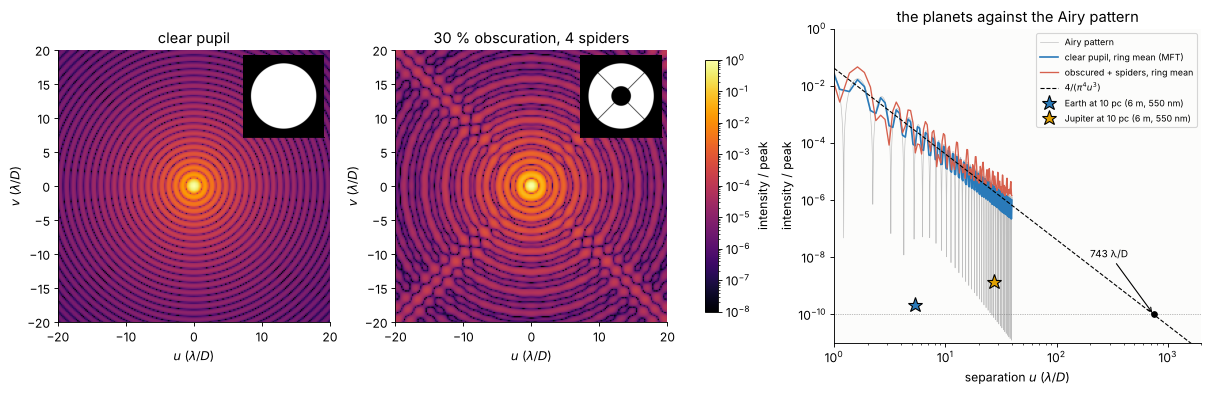

In [3]:
u = cg.pupil_grid(400, 80)                 # final focal plane, +-40 lambda/D, 0.2 lambda/D steps
P_obs = cg.telescope_pupil(x, x, obscuration=0.3, n_spiders=4, spider_width=0.01, spider_angle=np.pi/4,
                           oversample=16)
tel = cg.Coronagraph(x, x, P)
tel_obs = cg.Coronagraph(x, x, P_obs)
I_clear = tel.image(u, u)
I_obs = tel_obs.image(u, u)

edges = np.arange(0.5, 40.0, 0.25)
rc, p_clear = cg.radial_profile(I_clear, u, u, edges)
_, p_obs = cg.radial_profile(I_obs, u, u, edges)
uu = np.linspace(0.01, 40, 4000)
airy = (2*j1(np.pi*uu)/(np.pi*uu))**2
# ring means of the sampled pattern against the exact ring means of the Airy pattern (1 lambda/D rings)
e1 = np.arange(5.0, 41.0, 1.0)
r1, p1 = cg.radial_profile(I_clear, u, u, e1)
airy_ring = np.array([np.sum(2*np.pi*s*(2*j1(np.pi*s)/(np.pi*s))**2)/np.sum(2*np.pi*s)
                      for s in [np.linspace(a, b, 400) for a, b in zip(e1[:-1], e1[1:])]])

u_1e10 = (4/(np.pi**4*1e-10))**(1/3)
print("peak of the obscured pupil relative to the clear one: {:.3f} (open area squared: {:.3f})".format(
    tel_obs.peak/tel.peak, (P_obs.sum()/P.sum())**2))
print("ring means 5-40 lambda/D (1 lambda/D wide), numerical/exact Airy: {:.3f} ... {:.3f}".format(
    np.min(p1/airy_ring), np.max(p1/airy_ring)))
print("Airy envelope 4/(pi^4 u^3) reaches 1e-10 at u = {:.0f} lambda/D".format(u_1e10))
print("Airy envelope at the Earth (5.3 lambda/D): {:.1e}, at Jupiter (27 lambda/D): {:.1e}".format(
    cg.airy_envelope(5.3), cg.airy_envelope(27.5)))

fig = plt.figure(figsize=(15, 4.8), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.35])
ext = [u[0], u[-1], u[0], u[-1]]
for k, (I, ttl) in enumerate(((I_clear, "clear pupil"), (I_obs, "30 % obscuration, 4 spiders"))):
    a = fig.add_subplot(gs[k])
    im = a.imshow(I, extent=ext, origin="lower", norm=LogNorm(1e-8, 1), cmap="inferno")
    a.set_xlim(-20, 20); a.set_ylim(-20, 20)
    a.set_title(ttl); a.set_xlabel(r"$u$ ($\lambda/D$)"); a.set_ylabel(r"$v$ ($\lambda/D$)")
    ins = a.inset_axes([0.68, 0.68, 0.3, 0.3])
    ins.imshow(P if k == 0 else P_obs, extent=[x[0], x[-1], x[0], x[-1]], cmap="gray", origin="lower")
    ins.set_xticks([]); ins.set_yticks([])
fig.colorbar(im, ax=fig.axes[:2], shrink=0.8, label="intensity / peak")
a = fig.add_subplot(gs[2])
uu2 = np.geomspace(1, 2000, 400)
a.loglog(uu, airy, color="0.75", lw=0.6, label="Airy pattern")
a.loglog(rc, p_clear, color=BLUE, lw=1.5, label="clear pupil, ring mean (MFT)")
a.loglog(rc, p_obs, color=RED, lw=1.2, label="obscured + spiders, ring mean")
a.loglog(uu2, cg.airy_envelope(uu2), "k--", lw=1, label=r"$4/(\pi^4u^3)$")
for name, c in (("Earth", BLUE), ("Jupiter", ORANGE)):
    C, sep = contrasts[name]
    s = sep/lod["6 m, 550 nm"]
    a.plot(s, C, "*", ms=14, color=c, mec="k", label="{} at 10 pc (6 m, 550 nm)".format(name))
a.axhline(1e-10, color=GREY, lw=0.6, ls=":")
a.plot(u_1e10, 1e-10, "o", color="k", ms=5)
a.annotate("{:.0f} λ/D".format(u_1e10), (u_1e10, 1e-10), (200, 1e-8), arrowprops=dict(arrowstyle="->"), fontsize=9)
a.set_xlim(1, 2000); a.set_ylim(1e-11, 1)
a.set_xlabel(r"separation $u$ ($\lambda/D$)"); a.set_ylabel("intensity / peak")
a.legend(fontsize=8, loc="upper right"); a.set_title("the planets against the Airy pattern")
plt.show()

The ring means of the sampled pupil follow those of the exact Airy
pattern within 7 % (the ratio printed above), and both follow
$4/(\pi^4u^3)$. The Earth twin
is $2\times10^{-10}$ where the Airy rings are at $3\times10^{-4}$, six orders of
magnitude brighter, and the rings reach the Earth's level only at 740
$\lambda/D$, 14 arcseconds out. The obscured pupil spreads more light into
the rings (the obscuration takes light out of the core, so the peak drops
to $(1-0.3^2)^2$, less 4 % for the vanes) and adds four diffraction spikes,
one along the normal of each pair of vane edges.

The aim of a coronagraph is a **dark hole**: a region a few to a few tens
of $\lambda/D$ from the star where its light is below $10^{-10}$, while a
planet there keeps most of its light.

## 2. Apodized pupils

The Airy rings come from the hard edge of the pupil: a step makes the
$u^{-3}$ wings. A pupil whose transmission falls smoothly to zero at the
rim has a PSF that falls faster. The Sonine apodizations
$A(r) = (1-4r^2/D^2)^\nu$ have the analytic PSF (`cg.sonine_psf()`)

$$\frac{I(u)}{I(0)} = \left[\Gamma(\nu+2)\,2^{\nu+1}\,\frac{J_{\nu+1}(\pi u)}{(\pi u)^{\nu+1}}\right]^2,$$

whose rings fall as $u^{-(2\nu+3)}$. The price: the transmitted light is
$1/(2\nu+1)$ of the clear pupil, the peak $1/(\nu+1)^2$, and the core is
wider.

The other classic is the circular **prolate spheroidal** apodizer of
Slepian, the pupil function that puts the largest fraction $\Lambda$ of its
light inside a disk of radius $a$ in the focal plane
(`cg.prolate_apodizer()`). It is the eigenfunction with the largest
eigenvalue of "Fourier transform, keep the disk, transform back, keep the
pupil"; $\Lambda$ is that eigenvalue.

 nu   peak (num.)  1/(nu+1)^2   power (num.)  1/(2nu+1)   u at 1e-10 (envelope)
  0      1.0000       1.0000        1.0000       1.0000         743.3
  1      0.2500       0.2500        0.3342       0.3333          58.2
  2      0.1111       0.1111        0.2005       0.2000          21.9
  3      0.0625       0.0625        0.1432       0.1429          13.6

prolate apodizers
 a (lambda/D)  Lambda      encircled energy in a (MFT)   peak    power


    1        0.907293       0.907161                    0.367   0.409
    2        0.999524       0.999522                    0.101   0.176


    3        0.999999       0.999999                    0.045   0.113


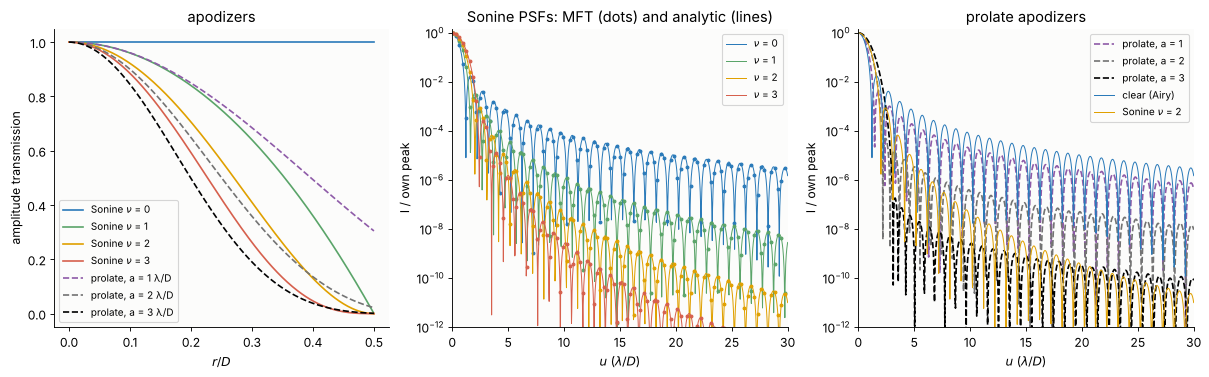

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
r_line = np.linspace(0, 0.5, 300)
u_line = np.linspace(0.05, 30, 1200)
c = len(x)//2
print(" nu   peak (num.)  1/(nu+1)^2   power (num.)  1/(2nu+1)   u at 1e-10 (envelope)")
for nu, col in zip((0, 1, 2, 3), (BLUE, GREEN, ORANGE, RED)):
    A = cg.sonine_apodizer(x, x, nu)
    co = cg.Coronagraph(x, x, P, apodizer=A)
    I = np.abs(cg.mft(P*A, x, x, u_line, [0.0])[0])**2/co.peak
    ax[0].plot(r_line, (1 - 4*r_line**2)**nu, color=col, label=r"Sonine $\nu$ = {}".format(nu))
    ax[1].semilogy(u_line[::12], I[::12], "o", ms=2.5, color=col)
    ax[1].semilogy(u_line, cg.sonine_psf(u_line, nu), color=col, lw=0.9, label=r"$\nu$ = {}".format(nu))
    env = lambda s: (gamma(nu + 2)*2**(nu + 1))**2/(np.pi*(np.pi*s)**(2*nu + 3))
    print("{:3d}    {:8.4f}     {:8.4f}      {:8.4f}     {:8.4f}       {:7.1f}".format(
        nu, co.peak/tel.peak, 1/(nu + 1)**2, co.throughput, 1/(2*nu + 1),
        brentq(lambda s: np.log(env(s)/1e-10), 0.5, 1e4)))
ax[1].set_ylim(1e-12, 1.5); ax[1].set_xlim(0, 30)
ax[1].set_xlabel(r"$u$ ($\lambda/D$)"); ax[1].set_ylabel("I / own peak"); ax[1].legend(fontsize=9)
ax[1].set_title("Sonine PSFs: MFT (dots) and analytic (lines)")

print("\nprolate apodizers")
print(" a (lambda/D)  Lambda      encircled energy in a (MFT)   peak    power")
for a_m, col in zip((1.0, 2.0, 3.0), (PURPLE, GREY, "k")):
    pro, A = cg.prolate_apodizer(a_m, x, x)
    co = cg.Coronagraph(x, x, P, apodizer=A)
    ug = cg.pupil_grid(256, 2*a_m)
    F = cg.mft(P*A, x, x, ug, ug)
    UG, VG = np.meshgrid(ug, ug)
    ee = np.sum(np.abs(F)**2*cg.telescope_pupil(ug, ug, D=2*a_m, oversample=8))*(ug[1] - ug[0])**2/(np.sum(np.abs(P*A)**2)*dA)
    I = np.abs(cg.mft(P*A, x, x, u_line, [0.0])[0])**2/co.peak
    ax[0].plot(pro.r, pro.values, color=col, ls="--", label="prolate, a = {:.0f} λ/D".format(a_m))
    ax[2].semilogy(u_line, I, color=col, ls="--", label="prolate, a = {:.0f}".format(a_m))
    print("    {:.0f}        {:.6f}       {:.6f}                    {:.3f}   {:.3f}".format(
        a_m, pro.eigenvalue, ee, co.peak/tel.peak, co.throughput))
ax[2].semilogy(u_line, cg.sonine_psf(u_line, 0), color=BLUE, lw=0.9, label="clear (Airy)")
ax[2].semilogy(u_line, cg.sonine_psf(u_line, 2), color=ORANGE, lw=0.9, label=r"Sonine $\nu$ = 2")
ax[2].set_ylim(1e-12, 1.5); ax[2].set_xlim(0, 30); ax[2].legend(fontsize=9)
ax[2].set_xlabel(r"$u$ ($\lambda/D$)"); ax[2].set_ylabel("I / own peak"); ax[2].set_title("prolate apodizers")
ax[0].set_xlabel(r"$r/D$"); ax[0].set_ylabel("amplitude transmission"); ax[0].legend(fontsize=9)
ax[0].set_title("apodizers")
plt.show()

The MFT of the sampled pupils lies on the analytic Sonine PSFs, and the
peaks and transmitted powers are $1/(\nu+1)^2$ and $1/(2\nu+1)$ to the
third decimal. The encircled energy of the prolate apodizers inside $a$
agrees with the eigenvalue $\Lambda$ to $10^{-4}$ or better.

Apodization alone is not enough for an Earth twin. Even $\nu = 3$, which
passes only 14 % of the light, reaches $10^{-10}$ only beyond 14
$\lambda/D$ (table), and its core has grown to twice the width. The prolate
apodizers concentrate the light in their core but put the rest in rings
that fall as slowly as before ($\Lambda = 0.99952$ for $a=2$ still leaves
$5\times10^{-4}$ of the light outside). Apodization works best together with a
focal plane mask, in section 4.

## 3. The Lyot coronagraph

Lyot's coronagraph puts an opaque disk of radius $a\,\lambda/D$ on the image
of the star. The disk takes out the core, but the rings that pass the
disk still carry the high spatial frequencies of the sharp pupil edge. A
collimator images the pupil onto the **Lyot plane**, where this light
piles up near the rim of the pupil image, and a Lyot stop a little
smaller than the pupil image blocks it.

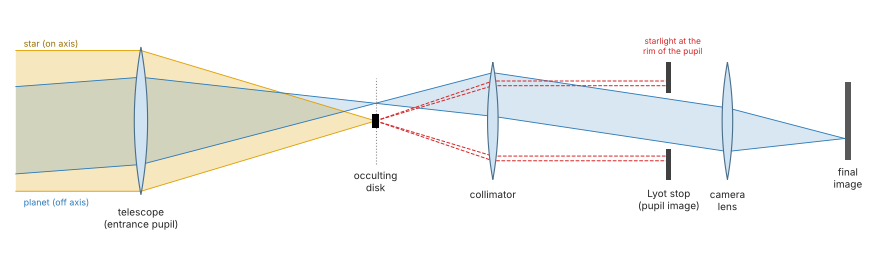

In [5]:
fig, ax = plt.subplots(figsize=(14, 4.4))
sketch.coronagraph_layout(ax, mask="lyot")
plt.show()

By Babinet's principle the field behind the disk is the incoming field
minus the part that falls on the disk: $E_L = E - \mathcal F^{-1}[M\,\mathcal F[E]]$.
Only the light on the disk has to be transformed, on a fine grid over the
disk alone (`cg.occulter_lyot_field()`, Soummer et al. 2007). For the
clear pupil the focal field is $J_1(\pi\rho)/(2\rho)$, and the part on the
disk returns to the Lyot plane as the Hankel integral

$$E_L(r) = P(r) - \pi\int_0^a J_0(2\pi\rho r)\,J_1(\pi\rho)\,d\rho$$

(`cg.occulter_lyot_analytic()`). At the centre of the pupil the integral
is $1 - J_0(\pi a)$, so the field left there is exactly $J_0(\pi a)$: it
falls slowly with the size of the disk and changes sign.

 a (lambda/D)   E_L(0) (MFT)    J0(pi a)    max |MFT - Hankel| for r < 0.45 D
      1        -0.30417      -0.30424      4.9e-05
      2        +0.22010      +0.22028      1.4e-04
      3        -0.18096      -0.18121      1.8e-04
      5        -0.14075      -0.14118      2.8e-04


      8        +0.11116      +0.11197      5.2e-04


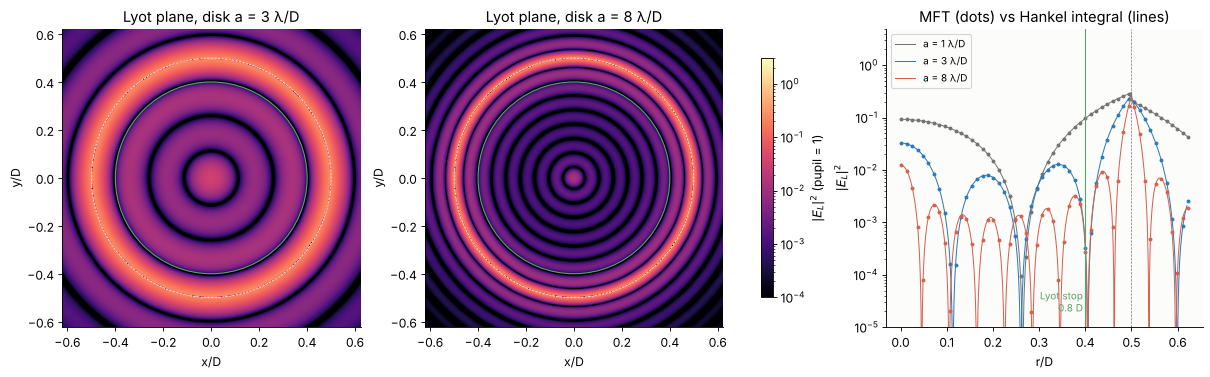

In [6]:
print(" a (lambda/D)   E_L(0) (MFT)    J0(pi a)    max |MFT - Hankel| for r < 0.45 D")
cut = x[c:]
fields = {}
for a_m in (1.0, 2.0, 3.0, 5.0, 8.0):
    EL = cg.occulter_lyot_field(P, x, x, a_m)
    fields[a_m] = EL
    ana = cg.occulter_lyot_analytic(np.abs(cut), a_m)
    print("    {:3.0f}        {:+.5f}      {:+.5f}      {:.1e}".format(
        a_m, EL[c, c].real, j0(np.pi*a_m), np.max(np.abs(EL[c, c:].real - ana)[np.abs(cut) < 0.45])))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
ext_p = [x[0], x[-1], x[0], x[-1]]
for a_ax, a_m in zip(ax[:2], (3.0, 8.0)):
    im = a_ax.imshow(np.abs(fields[a_m])**2, extent=ext_p, origin="lower", norm=LogNorm(1e-4, 3), cmap="magma")
    a_ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="w", lw=0.6, ls="--"))
    a_ax.add_patch(plt.Circle((0, 0), 0.4, fill=False, color=GREEN, lw=1.0))
    a_ax.set_title("Lyot plane, disk a = {:.0f} λ/D".format(a_m))
    a_ax.set_xlabel("x/D"); a_ax.set_ylabel("y/D")
fig.colorbar(im, ax=ax[:2], shrink=0.8, label=r"$|E_L|^2$ (pupil = 1)")
rr = np.linspace(0, 0.62, 600)
for a_m, col in ((1.0, GREY), (3.0, BLUE), (8.0, RED)):
    ax[2].semilogy(np.abs(cut[::3]), np.abs(fields[a_m][c, c::3])**2, "o", ms=2.5, color=col)
    ax[2].semilogy(rr, np.abs(cg.occulter_lyot_analytic(rr, a_m))**2, color=col, lw=0.9,
                   label="a = {:.0f} λ/D".format(a_m))
ax[2].axvline(0.5, color=GREY, lw=0.6, ls="--"); ax[2].axvline(0.4, color=GREEN, lw=1.0)
ax[2].text(0.395, 2e-5, "Lyot stop\n0.8 D", color=GREEN, ha="right", fontsize=9)
ax[2].set_ylim(1e-5, 5); ax[2].set_xlabel("r/D"); ax[2].set_ylabel(r"$|E_L|^2$")
ax[2].set_title("MFT (dots) vs Hankel integral (lines)"); ax[2].legend(fontsize=9)
plt.show()

The field at the centre of the pupil is $J_0(\pi a)$ to four digits, and
the whole radial profile agrees with the Hankel integral to $10^{-4}$.
Most of the light that passes the disk is in a bright ring around the
rim of the pupil image, but inside it the field falls only slowly with
the disk size, $|J_0(\pi a)|^2 \approx 2/(\pi^2 a)$: 3 % of the intensity for
$a = 3$, 0.8 % for $a = 8$. A Lyot stop removes the ring, the inside
passes. Below, the contrast in the final image and the throughput for a
disk of $3\,\lambda/D$ and Lyot stops of 100 % to 70 % of the pupil
diameter. The contrast is the intensity relative to the peak of an
off-axis source far from the mask, which passes the same Lyot stop.

Lyot stop   throughput   mean contrast 4-6 lambda/D   10-15 lambda/D
  100%        0.998            1.1e-04                5.8e-06


  90%        0.810            2.7e-05                1.4e-06
  80%        0.640            1.3e-05                1.4e-07


  70%        0.489            3.6e-05                8.7e-07


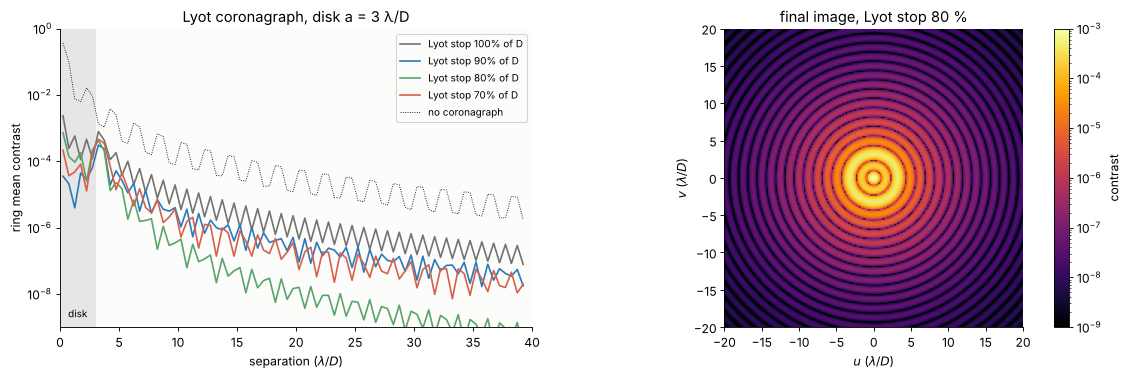

In [7]:
edges_c = np.arange(0.0, 40.0, 0.5)
lyots = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
print("Lyot stop   throughput   mean contrast 4-6 lambda/D   10-15 lambda/D")
for d_s, col in ((1.0, GREY), (0.9, BLUE), (0.8, GREEN), (0.7, RED)):
    stop = cg.telescope_pupil(x, x, D=d_s, oversample=8)
    co = cg.Coronagraph(x, x, P, "lyot", mask_radius=3.0, lyot_stop=stop)
    I = co.image(u, u)
    rc, p = cg.radial_profile(I, u, u, edges_c)
    lyots[d_s] = (co, I, p)
    ax[0].semilogy(rc, p, color=col, label="Lyot stop {:.0%} of D".format(d_s))
    print("  {:.0%}        {:.3f}            {:.1e}                {:.1e}".format(
        d_s, co.throughput, np.mean(p[(rc > 4) & (rc < 6)]), np.mean(p[(rc > 10) & (rc < 15)])))
ax[0].semilogy(rc, p_clear[:len(rc)] if len(p_clear) >= len(rc) else np.interp(rc, edges[:-1] + 0.125, p_clear),
               color="k", lw=0.8, ls=":", label="no coronagraph")
ax[0].axvspan(0, 3, color="0.9")
ax[0].text(1.5, 2e-9, "disk", ha="center", fontsize=9)
ax[0].set_ylim(1e-9, 1); ax[0].set_xlim(0, 40)
ax[0].set_xlabel(r"separation ($\lambda/D$)"); ax[0].set_ylabel("ring mean contrast")
ax[0].legend(fontsize=9); ax[0].set_title("Lyot coronagraph, disk a = 3 λ/D")
im = ax[1].imshow(lyots[0.8][1], extent=ext, origin="lower", norm=LogNorm(1e-9, 1e-3), cmap="inferno")
ax[1].set_xlim(-20, 20); ax[1].set_ylim(-20, 20)
ax[1].set_xlabel(r"$u$ ($\lambda/D$)"); ax[1].set_ylabel(r"$v$ ($\lambda/D$)")
ax[1].set_title("final image, Lyot stop 80 %")
fig.colorbar(im, ax=ax[1], label="contrast")
plt.show()

Without a Lyot stop the disk only takes the core away; the rings stay at
the level of the Airy pattern. A stop of 90 % removes most of the ring at
the rim and gains two orders of magnitude, but the light inside the
pupil, $J_0(\pi a)$ and its ripples, is a field that the camera lens
images as a smaller copy of the star, with its own rings. A smaller stop
cuts more of the ring at the rim but makes the image of the leftover
field wider; 80 % is best here. The classical Lyot coronagraph stalls at
about $10^{-5}$ near 5 $\lambda/D$ and $10^{-7}$ beyond 10 $\lambda/D$. That
is enough for the solar corona and for young giant planets, not for an
Earth.

A planet at a separation $\alpha$ is a tilted plane wave
$e^{2\pi i \alpha x}$ (`cg.tilt()`), focused at $u = \alpha$. Its throughput
is the peak of its image relative to a source far from the mask:

In [8]:
seps = np.linspace(0, 12, 49)
def planet_throughput(co, seps):
    out = []
    for s in seps:
        us = np.linspace(s - 1.5, s + 1.5, 31)
        out.append(co.image(us, np.linspace(-1.5, 1.5, 31), cg.tilt(x, x, s)).max())
    return np.array(out)
thr_lyot = planet_throughput(lyots[0.8][0], seps)
for s in (2.0, 3.0, 4.0, 6.0, 10.0):
    print("planet at {:4.1f} lambda/D: {:.2f} of the peak behind the same Lyot stop".format(
        s, np.interp(s, seps, thr_lyot)))
iwa = lambda thr: brentq(lambda s: np.interp(s, seps, thr) - 0.5*thr[-1], 0.05, 8)
print("50 % of the light (inner working angle) at {:.2f} lambda/D".format(iwa(thr_lyot)))

planet at  2.0 lambda/D: 0.01 of the peak behind the same Lyot stop
planet at  3.0 lambda/D: 0.30 of the peak behind the same Lyot stop
planet at  4.0 lambda/D: 1.00 of the peak behind the same Lyot stop
planet at  6.0 lambda/D: 1.01 of the peak behind the same Lyot stop
planet at 10.0 lambda/D: 1.00 of the peak behind the same Lyot stop
50 % of the light (inner working angle) at 3.20 lambda/D


The planet is lost behind the disk, comes out half way at 3.2 $\lambda/D$
(the **inner working angle**) and passes fully from 4 $\lambda/D$ on. The
Lyot stop costs every source the same 36 % of the light ($0.8^2$ passes),
which is in the normalization.

## 4. The apodized pupil Lyot coronagraph

The prolate apodizer of section 2 is the eigenfunction of exactly the
operation the Lyot coronagraph performs: transform, keep the disk of
radius $a$ (what the disk removes), transform back into the pupil. With
the apodizer $A$ in the entrance pupil and the disk of the same $a$, the
Babinet formula gives inside the pupil

$$E_L = A - \Lambda A = (1-\Lambda)\,A,$$

a scaled copy of the apodizer and no ring structure at all (Aime, Soummer
and Ferrari 2002; Soummer et al. 2003). The Lyot stop can then be nearly
the full pupil. The star's peak is the apodized peak times
$(1-\Lambda)^2$. This is the APLC of the Gemini Planet Imager and of
SPHERE. The residual is a small difference of large terms, so the check
uses finer pupils: 512 samples across for the field, and 256 to 1024 for
the peak, whose error comes from the pixelated rim and falls as $1/n$.

In [9]:
def aplc_check(n, a_m):
    xn = cg.pupil_grid(int(1.25*n), 1.25)
    Xn, Yn = np.meshgrid(xn, xn)
    Pn = cg.telescope_pupil(xn, xn, oversample=8)
    pro, An = cg.prolate_apodizer(a_m, xn, xn)
    EL = cg.occulter_lyot_field(Pn*An, xn, xn, a_m)
    inside = np.hypot(Xn, Yn) < 0.45
    return pro, np.median(EL[inside].real/An[inside]), np.abs(np.sum(EL*Pn))**2/np.abs(np.sum(Pn*An))**2

print(" a (lambda/D)   1 - Lambda    median E_L/A in r < 0.45 D (512 samples)")
for a_m in (1.0, 1.5, 2.0):
    pro, ratio, _ = aplc_check(512, a_m)
    print("    {:3.1f}         {:.3e}      {:.3e}".format(a_m, 1 - pro.eigenvalue, ratio))
print("\na = 2: peak with/without disk against (1-Lambda)^2 = {:.3e}".format((1 - pro.eigenvalue)**2))
peaks = {}
for n_s in (256, 512, 1024):
    peaks[n_s] = aplc_check(n_s, 2.0)[2]
    print("  {:4d} samples across D:  {:.3e}".format(n_s, peaks[n_s]))
print("  extrapolated, 2 p(1024) - p(512): {:.3e}".format(2*peaks[1024] - peaks[512]))

 a (lambda/D)   1 - Lambda    median E_L/A in r < 0.45 D (512 samples)


    1.0         9.271e-02      9.292e-02


    1.5         7.645e-03      7.737e-03


    2.0         4.759e-04      4.883e-04

a = 2: peak with/without disk against (1-Lambda)^2 = 2.265e-07
   256 samples across D:  1.027e-07


   512 samples across D:  1.555e-07


  1024 samples across D:  1.868e-07
  extrapolated, 2 p(1024) - p(512): 2.181e-07


The field behind the disk is $(1-\Lambda)$ times the apodizer within 3 %,
and the star's peak converges to $(1-\Lambda)^2 = 2.3\times10^{-7}$ as the
pupil is sampled more finely (the extrapolation from 512 and 1024 samples
is within 4 %). The errors of the pixelated rim sit at the rim, so a
Lyot stop of 98 % of the pupil hides them. The contrast curve, on the 256
sample grid:

In [10]:
pro2, A2 = cg.prolate_apodizer(2.0, x, x)
stop98 = cg.telescope_pupil(x, x, D=0.98, oversample=8)
aplc = cg.Coronagraph(x, x, P, "lyot", mask_radius=2.0, apodizer=A2, lyot_stop=stop98)
I_aplc = aplc.image(u, u)
_, p_aplc = cg.radial_profile(I_aplc, u, u, edges_c)
thr_aplc = planet_throughput(aplc, seps)
print("APLC a = 2: throughput {:.3f} (apodizer and Lyot stop), peak {:.3f} of the clear pupil".format(
    aplc.throughput, aplc.peak/tel.peak))
print("mean contrast 3-6 lambda/D: {:.1e}, 6-15 lambda/D: {:.1e}".format(
    np.mean(p_aplc[(rc > 3) & (rc < 6)]), np.mean(p_aplc[(rc > 6) & (rc < 15)])))
print("planet throughput at 2, 3, 4 lambda/D: " + ", ".join("{:.2f}".format(np.interp(s, seps, thr_aplc))
                                                       for s in (2, 3, 4)))
print("inner working angle {:.2f} lambda/D".format(iwa(thr_aplc)))

APLC a = 2: throughput 0.176 (apodizer and Lyot stop), peak 0.101 of the clear pupil
mean contrast 3-6 lambda/D: 1.3e-11, 6-15 lambda/D: 1.4e-12
planet throughput at 2, 3, 4 lambda/D: 0.55, 1.02, 1.00
inner working angle 1.94 lambda/D


The APLC with a disk of $2\,\lambda/D$ reaches the numerical floor,
$10^{-11}$ from 3 $\lambda/D$ outwards, six orders of magnitude below the
classical Lyot coronagraph with its larger disk, and its inner working
angle is 1.9 $\lambda/D$. The cost is the apodizer: it passes 18 % of the
light, and the peak of an off-axis planet is 10 % of what the clear
pupil gives (the contrast above is relative to that lower peak). The
APLCs of real instruments trade some contrast for throughput with
gentler apodizers, found by numerical optimization.

## 5. The vortex coronagraph

A vortex phase mask $e^{il\theta}$ in the focal plane (Mawet et al. 2005;
Foo, Palacios and Swartzlander 2005) has no opaque part. Notebook 69 made
vortices with spiral phase plates; here it is a focal plane mask, made in
practice from liquid crystal polymers or subwavelength gratings. For an
even charge $l$ and a clear circular pupil of radius $R = D/2$, the Lyot
plane field is zero inside the pupil, and outside

$$E_2 = -\left(\frac{R}{r}\right)^2 e^{2i\theta},\qquad
E_4 = \left[2\left(\frac{R}{r}\right)^2 - 3\left(\frac{R}{r}\right)^4\right] e^{4i\theta}$$

(`cg.vortex_lyot_analytic()`): all of the starlight is moved outside the
pupil, where a Lyot stop takes it out completely.

Numerically, the vortex is harder than a disk. Its field is singular at
the centre and the focal plane field must be followed out to large $u$
because nothing blocks it. `cg.vortex_lyot_field()` uses nested grids,
$1/512\,\lambda/D$ steps near the centre up to $1/4\,\lambda/D$ out to $128\,\lambda/D$,
joined with smooth windows that add up to one (after Krist et al. 2011).

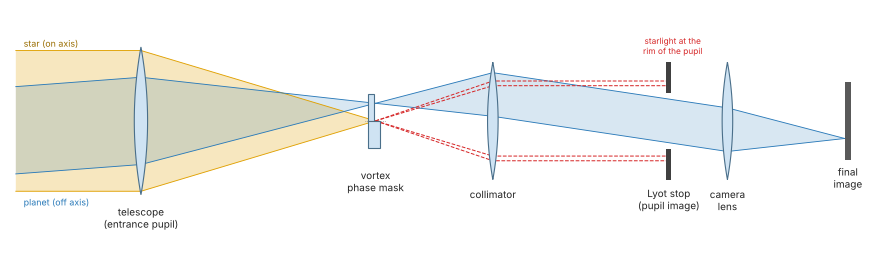

Lyot plane fields of three vortices: 0.7 s
charge   max |E_L|^2 for r < 0.45 D   max |num - analytic| for 0.52 < r < 0.6 D
  2          1.2e-07                    2.1e-03
  4          2.0e-07                    2.8e-03


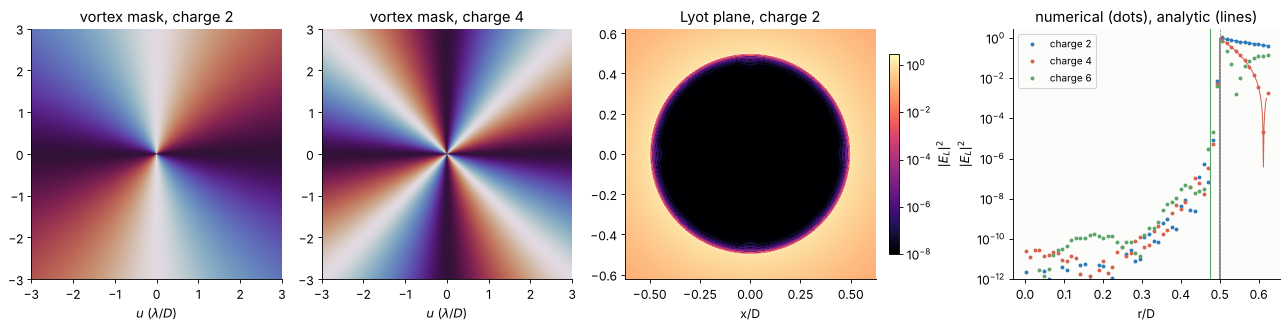

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.4))
sketch.coronagraph_layout(ax, mask="vortex")
plt.show()

stop95 = cg.telescope_pupil(x, x, D=0.95, oversample=8)
t0 = time.time()
vort = {l: cg.Coronagraph(x, x, P, "vortex", charge=l, lyot_stop=stop95) for l in (2, 4, 6)}
EL_v = {l: vort[l].lyot_field() for l in (2, 4, 6)}
print("Lyot plane fields of three vortices: {:.1f} s".format(time.time() - t0))
rr = np.linspace(0.0, 0.62, 400)
print("charge   max |E_L|^2 for r < 0.45 D   max |num - analytic| for 0.52 < r < 0.6 D")
for l in (2, 4):
    ana = cg.vortex_lyot_analytic(R, l)*np.exp(1j*l*np.arctan2(Y, X))
    ring = (R > 0.52) & (R < 0.6)
    print("  {}          {:.1e}                    {:.1e}".format(l, np.max(np.abs(EL_v[l][R < 0.45])**2),
                                                     np.max(np.abs(EL_v[l] - ana)[ring])))

fig, ax = plt.subplots(1, 4, figsize=(16, 4.0), layout="constrained")
uf = np.linspace(-3, 3, 301)
UF, VF = np.meshgrid(uf, uf)
for a_ax, l in zip(ax[:2], (2, 4)):
    a_ax.imshow(np.angle(np.exp(1j*l*np.arctan2(VF, UF))), extent=[-3, 3, -3, 3], origin="lower", cmap="twilight")
    a_ax.set_title("vortex mask, charge {}".format(l)); a_ax.set_xlabel(r"$u$ ($\lambda/D$)")
im = ax[2].imshow(np.abs(EL_v[2])**2, extent=ext_p, origin="lower", norm=LogNorm(1e-8, 3), cmap="magma")
ax[2].add_patch(plt.Circle((0, 0), 0.5, fill=False, color="w", lw=0.6, ls="--"))
ax[2].set_title("Lyot plane, charge 2"); ax[2].set_xlabel("x/D")
fig.colorbar(im, ax=ax[2], shrink=0.8, label=r"$|E_L|^2$")
for l, col in ((2, BLUE), (4, RED), (6, GREEN)):
    ax[3].semilogy(np.abs(cut[::3]), np.abs(EL_v[l][c, c::3])**2, "o", ms=2.5, color=col, label="charge {}".format(l))
for l, col in ((2, BLUE), (4, RED)):
    ax[3].semilogy(rr, cg.vortex_lyot_analytic(rr, l)**2, color=col, lw=0.9)
ax[3].axvline(0.5, color=GREY, lw=0.6, ls="--"); ax[3].axvline(0.475, color=GREEN, lw=1.0)
ax[3].set_ylim(1e-12, 3); ax[3].set_xlabel("r/D"); ax[3].set_ylabel(r"$|E_L|^2$")
ax[3].set_title("numerical (dots), analytic (lines)"); ax[3].legend(fontsize=9)
plt.show()

Outside the pupil the numerical fields agree with the analytic ones to
$3\times10^{-3}$, limited by the light beyond $128\,\lambda/D$ that the grids
leave out (it blurs the field near the rim). Inside, the starlight is
gone to below $10^{-7}$ of the pupil intensity, a numerical floor set by the
same blur and the sampled pupil edge. A Lyot stop of 95 % then leaves a
contrast in the final image of about $10^{-11}$, the floor of this model
and well below what we need:

charge   mean contrast 1-5 lambda/D   5-20 lambda/D


  2         6.2e-12                3.7e-12


  4         7.5e-12                7.0e-12


  6         7.5e-12                1.5e-11


charge 2: 50 % throughput (inner working angle) at 1.23 lambda/D, 0.88 at 4 lambda/D
charge 4: 50 % throughput (inner working angle) at 2.38 lambda/D, 0.69 at 4 lambda/D
charge 6: 50 % throughput (inner working angle) at 3.33 lambda/D, 0.53 at 4 lambda/D


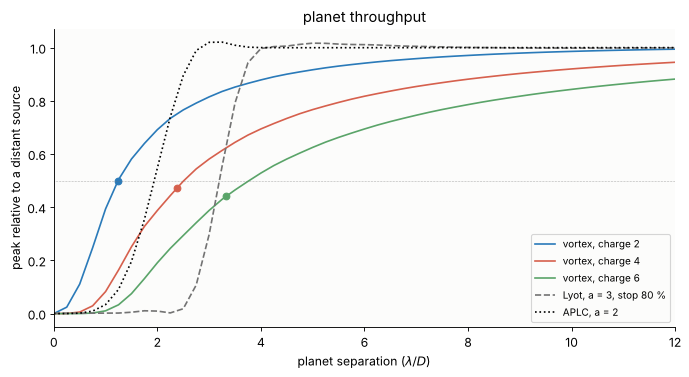

In [12]:
print("charge   mean contrast 1-5 lambda/D   5-20 lambda/D")
I_v = {}
for l in (2, 4, 6):
    I_v[l] = vort[l].image(u, u)
    _, p = cg.radial_profile(I_v[l], u, u, edges_c)
    print("  {}         {:.1e}                {:.1e}".format(l, np.nanmean(p[(rc > 1) & (rc < 5)]),
                                                         np.nanmean(p[(rc > 5) & (rc < 20)])))
thr_v = {l: planet_throughput(vort[l], seps) for l in (2, 4, 6)}

fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
for l, col in ((2, BLUE), (4, RED), (6, GREEN)):
    ax.plot(seps, thr_v[l], color=col, label="vortex, charge {}".format(l))
    ax.plot(iwa(thr_v[l]), 0.5*thr_v[l][-1], "o", color=col)
    print("charge {}: 50 % throughput (inner working angle) at {:.2f} lambda/D, {:.2f} at 4 lambda/D".format(
        l, iwa(thr_v[l]), np.interp(4.0, seps, thr_v[l])))
ax.plot(seps, thr_lyot, color=GREY, ls="--", label="Lyot, a = 3, stop 80 %")
ax.plot(seps, thr_aplc, color="k", ls=":", label="APLC, a = 2")
ax.axhline(0.5, color=GREY, lw=0.5, ls=":")
ax.set_xlabel(r"planet separation ($\lambda/D$)"); ax.set_ylabel("peak relative to a distant source")
ax.legend(fontsize=9); ax.set_title("planet throughput"); ax.set_xlim(0, 12)
plt.show()

The vortex lets a planet through closer to the star than a disk of the
same contrast: charge 2 passes half of the peak at 1.2 $\lambda/D$, charge
4 at 2.4 and charge 6 at 3.3 $\lambda/D$. It has no hard edge, though:
the throughput creeps up slowly, and at 4 $\lambda/D$ charge 6 still
passes only half. The occulting masks cut sharply, with a little
overshoot just outside the disk where the edge of the mask diffracts
light into the planet's core. The price of the small inner working
angle of charge 2 shows in the next section.

First, the pupil. The analytic null holds for a clear circle. A central
obscuration of diameter $\varepsilon D$ is a negative disk added to the
pupil; by linearity the vortex sends the field of that small disk out
over the whole Lyot plane, as $-(\varepsilon R/r)^2$ for charge 2, and
inside the pupil it is not blocked. The leaked fraction of the
starlight is the integral of $|E_l|^2$ for the small disk over the open part
of the Lyot stop:

In [13]:
print("obscuration  stop hole   charge   leak (numerical)   leak (analytic)")
for eps in (0.1, 0.2, 0.3):
    Pe = cg.telescope_pupil(x, x, obscuration=eps, oversample=16)
    for hole in (1.0, 1.5):
        st = cg.telescope_pupil(x, x, D=0.95, obscuration=eps*hole/0.95, oversample=8)
        for l in (2, 4):
            co = cg.Coronagraph(x, x, Pe, "vortex", charge=l, lyot_stop=st)
            leak = np.sum(np.abs(co.lyot_field()*st)**2)/np.sum(Pe**2)
            rr_ = np.linspace(eps*hole/2, 0.475, 4000)
            ana = np.trapezoid(cg.vortex_lyot_analytic(rr_, l, D=eps)**2*2*np.pi*rr_, rr_)/(np.pi/4*(1 - eps**2))
            print("   {:.1f}        {:.1f} x eps      {}        {:.2e}            {:.2e}".format(eps, hole, l, leak, ana))

obscuration  stop hole   charge   leak (numerical)   leak (analytic)


   0.1        1.0 x eps      2        9.49e-03            9.97e-03


   0.1        1.0 x eps      4        9.21e-03            9.64e-03


   0.1        1.5 x eps      2        4.32e-03            4.38e-03


   0.1        1.5 x eps      4        8.18e-03            8.21e-03


   0.2        1.0 x eps      2        3.88e-02            3.98e-02
   0.2        1.0 x eps      4        3.38e-02            3.47e-02


... (2 outputs left out)

   0.3        1.0 x eps      2        8.75e-02            8.90e-02


   0.3        1.0 x eps      4        6.35e-02            6.50e-02


   0.3        1.5 x eps      2        3.39e-02            3.41e-02


   0.3        1.5 x eps      4        5.08e-02            5.08e-02


A 30 % obscuration leaks 5 to 9 % of the starlight, a contrast near
$10^{-3}$: the vortex on its own is for unobscured telescopes (off-axis
designs such as the HabEx concept), or it needs pupil remapping or
apodization for the obscuration. A Lyot stop with a larger hole helps
charge 2 more than charge 4, whose leak spreads further out.

## 6. Pointing and low order aberrations

A small pointing error $\alpha$ tilts the star's wavefront,
$e^{2\pi i\alpha x} \approx 1 + 2\pi i\alpha x - (2\pi\alpha x)^2/2$. The vortex
nulls the constant term exactly. The selection rule (`cg.vortex_blocks()`)
says which other terms it nulls: a Zernike term $Z_n^m$ in the pupil makes
the focal field $J_{n+1}(\pi\rho)/\rho\;e^{im\phi}$; the vortex adds $e^{il\phi}$,
and the Weber–Schafheitlin integral that takes the result back into the
pupil vanishes inside it when $|m+l| - (n+1)$ is odd and positive. For a
real Zernike term that is

$$n + |m| < |l| .$$

Charge 2 blocks only piston, so tip and tilt leak to first order. Of the
tilt term, one helical half $r e^{-i\theta}$ passes with unit amplitude
into $r e^{i\theta}$ and the other half is blocked; with a Lyot stop of
diameter $D_L$ the leaked fraction is

$$L_2 = \frac{\pi^2\alpha^2}{8}\left(\frac{D_L}{D}\right)^4 .$$

Charge 4 blocks tip, tilt and defocus. Its leak comes from the astigmatic
part of $-(2\pi\alpha x)^2/2$, of which again one helical half passes:

$$L_4 = \frac{\pi^4\alpha^4}{192}\left(\frac{D_L}{D}\right)^6 .$$

6.4 s
  alpha     vortex 2   pi^2 a^2/8 (DL/D)^4    vortex 4   pi^4 a^4/192 (DL/D)^6
  0.009    9.019e-05     9.044e-05            3.339e-08     3.021e-09
  0.030    9.011e-04     9.044e-04            3.305e-07     3.021e-07
  0.095    8.958e-03     9.044e-03            2.987e-05     3.021e-05
  0.300    8.451e-02     9.044e-02            2.815e-03     3.021e-03


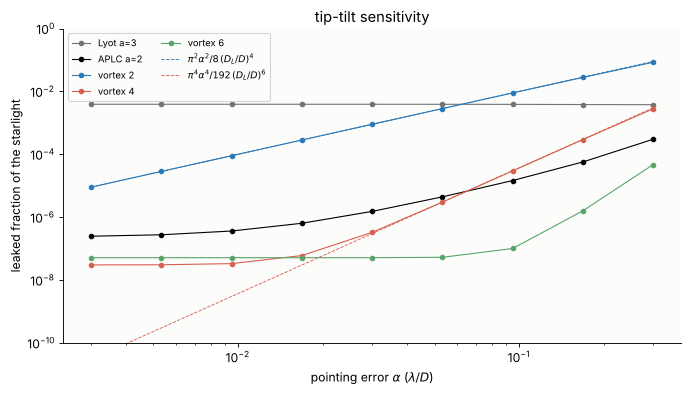

In [14]:
def leak(co, E=None):
    # fraction of the starlight that passes the Lyot stop
    return np.sum(np.abs(co.lyot_field(E)*co.lyot_stop)**2)/np.sum(np.abs(co.pupil_field())**2)

alphas = np.geomspace(0.003, 0.3, 9)
lyot80 = lyots[0.8][0]
leaks = {}
t0 = time.time()
for name, co in (("Lyot a=3", lyot80), ("APLC a=2", aplc), ("vortex 2", vort[2]), ("vortex 4", vort[4]),
                 ("vortex 6", vort[6])):
    leaks[name] = np.array([leak(co, cg.tilt(x, x, a)) for a in alphas])
print("{:.1f} s".format(time.time() - t0))
L2 = np.pi**2*alphas**2/8*0.95**4
L4 = np.pi**4*alphas**4/192*0.95**6
print("  alpha     vortex 2   pi^2 a^2/8 (DL/D)^4    vortex 4   pi^4 a^4/192 (DL/D)^6")
for k in (2, 4, 6, 8):
    print("  {:.3f}    {:.3e}     {:.3e}            {:.3e}     {:.3e}".format(
        alphas[k], leaks["vortex 2"][k], L2[k], leaks["vortex 4"][k], L4[k]))

fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
cols = {"Lyot a=3": GREY, "APLC a=2": "k", "vortex 2": BLUE, "vortex 4": RED, "vortex 6": GREEN}
for name, L in leaks.items():
    ax.loglog(alphas, L, "o-", color=cols[name], ms=4, lw=1, label=name)
ax.loglog(alphas, L2, "--", color=BLUE, lw=0.8, label=r"$\pi^2\alpha^2/8\,(D_L/D)^4$")
ax.loglog(alphas, L4, "--", color=RED, lw=0.8, label=r"$\pi^4\alpha^4/192\,(D_L/D)^6$")
ax.set_xlabel(r"pointing error $\alpha$ ($\lambda/D$)"); ax.set_ylabel("leaked fraction of the starlight")
ax.legend(fontsize=8.5, ncol=2); ax.set_title("tip-tilt sensitivity"); ax.set_ylim(1e-10, 1)
plt.show()

The leaks of charge 2 and charge 4 follow the two formulas, as
$\alpha^2$ and $\alpha^4$, within 1 % up to 0.1 $\lambda/D$ (higher orders
take over beyond, and charge 4 sits on the numerical floor below 0.02). Charge 6 leaks as $\alpha^6$ and stays at the numerical
floor (a leaked fraction near $5\times10^{-8}$, light spread far from the
star) down to 0.03 $\lambda/D$. The classical Lyot coronagraph leaks a constant
$4\times10^{-3}$, the light its design lets past the Lyot stop, which a
small pointing error hardly changes. The APLC starts from $2\times10^{-7}$
and leaks as $\alpha^2$ above 0.02 $\lambda/D$: its residual is a
balance between the apodizer and the disk that a shifted star upsets.

For a 6 m telescope at 550 nm, 0.01 $\lambda/D$ is 0.2 mas: a charge 2
vortex then leaks $10^{-4}$ of the light, which is why space coronagraphs
use charge 4 or 6 and accept the larger inner working angle.

The selection rule, checked term by term: each Fringe Zernike with 0.01
rad rms in the pupil, the leaked fraction divided by the variance
$\varepsilon^2$. A blocked term leaks only at second order, a few $10^{-4}$
in these units (at the numerical floor).

In [15]:
eps = 0.01
inside = R < 0.5
print(" j   n   m    leak/eps^2:  charge 2   charge 4   charge 6    blocked (n+|m| < l): 2, 4, 6")
for j in range(2, 17):
    n_z, m_z = fringe_to_n_m(j)
    Z = fringe_zernike(j, X/0.5, Y/0.5)
    Z = Z/np.sqrt(np.sum(Z**2*P)/np.sum(P))           # unit rms over the pupil
    row = [leak(vort[l], np.exp(1j*eps*Z))/eps**2 for l in (2, 4, 6)]
    rule = ["  yes " if cg.vortex_blocks(l, n_z, m_z) else "  no  " for l in (2, 4, 6)]
    ok = all((r_ < 0.01) == cg.vortex_blocks(l, n_z, m_z) for r_, l in zip(row, (2, 4, 6)))
    print("{:2d}  {:2d}  {:+2d}               {:8.2e}   {:8.2e}   {:8.2e}    {}{}".format(
        j, n_z, m_z, *row, "".join(rule), "" if ok else "  <-- mismatch"))

 j   n   m    leak/eps^2:  charge 2   charge 4   charge 6    blocked (n+|m| < l): 2, 4, 6


 2   1  +1               4.06e-01   3.10e-04   5.15e-04      no    yes   yes 


 3   1  -1               4.06e-01   3.10e-04   5.15e-04      no    yes   yes 


 4   2  +0               7.31e-01   3.15e-04   5.15e-04      no    yes   yes 


 5   2  +2               3.79e-01   3.66e-01   5.22e-04      no    no    yes 


 6   2  -2               3.79e-01   3.66e-01   5.24e-04      no    no    yes 


... (6 outputs left out)

13   4  -2               6.61e-01   3.51e-01   2.96e-01      no    no    no  


14   5  +1               7.18e-01   6.12e-01   2.67e-01      no    no    no  


15   5  -1               7.18e-01   6.12e-01   2.67e-01      no    no    no  


16   6  +0               7.61e-01   6.86e-01   4.79e-01      no    no    no  


Every term that the rule blocks leaks at most $5\times10^{-4}\varepsilon^2$,
and every term it passes leaks between 0.27 and 0.76 of its variance.
Charge 4 is insensitive to tip, tilt and defocus, charge 6 also to
astigmatism, coma and spherical aberration, but none of them to trefoil.

Pointing jitter blurs the coronagraphic image over the distribution of
tilts. Below, the contrast curves of all coronagraphs with a jitter of
0.02 $\lambda/D$ rms per axis (0.4 mas for 6 m at 550 nm), averaged with a
4 × 4 Gauss–Hermite rule, which is exact for leaks up to $\alpha^6$:

jitter averages: 13 s


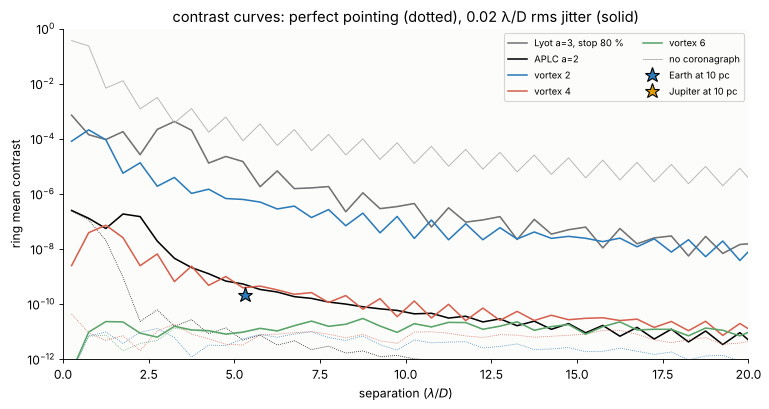

Lyot a=3, stop 80 %    contrast at 2-3, 4-6 lambda/D with jitter: 1.2e-04, 1.3e-05
APLC a=2               contrast at 2-3, 4-6 lambda/D with jitter: 8.4e-08, 7.0e-10
vortex 2               contrast at 2-3, 4-6 lambda/D with jitter: 7.7e-06, 8.2e-07
vortex 4               contrast at 2-3, 4-6 lambda/D with jitter: 4.5e-09, 5.8e-10
vortex 6               contrast at 2-3, 4-6 lambda/D with jitter: 7.5e-12, 1.0e-11


In [16]:
gh, wgh = np.polynomial.hermite_e.hermegauss(4)
wgh = wgh/wgh.sum()
sigma = 0.02
uj = cg.pupil_grid(200, 40)
def jittered(co, sigma):
    I = 0
    for a, wa in zip(gh, wgh):
        for b, wb in zip(gh, wgh):
            I = I + wa*wb*co.image(uj, uj, cg.tilt(x, x, sigma*a, sigma*b))
    return I
t0 = time.time()
curves = {}
for name, co in (("Lyot a=3, stop 80 %", lyot80), ("APLC a=2", aplc), ("vortex 2", vort[2]),
                 ("vortex 4", vort[4]), ("vortex 6", vort[6])):
    Ij = jittered(co, sigma)
    curves[name] = cg.radial_profile(Ij, uj, uj, edges_c)[1], cg.radial_profile(co.image(uj, uj), uj, uj, edges_c)[1]
print("jitter averages: {:.0f} s".format(time.time() - t0))

fig, ax = plt.subplots(figsize=(9.5, 5.0), layout="constrained")
cols2 = dict(zip(curves, (GREY, "k", BLUE, RED, GREEN)))
for name, (pj, p0) in curves.items():
    ax.semilogy(rc, pj, color=cols2[name], lw=1.4, label=name)
    ax.semilogy(rc, p0, color=cols2[name], lw=0.7, ls=":")
ax.semilogy(rc, np.interp(rc, edges[:-1] + 0.125, p_clear), color="0.7", lw=0.8, label="no coronagraph")
ax.plot(5.3, contrasts["Earth"][0], "*", ms=14, color=BLUE, mec="k", label="Earth at 10 pc")
ax.plot(27.5, contrasts["Jupiter"][0], "*", ms=14, color=ORANGE, mec="k", label="Jupiter at 10 pc")
ax.set_ylim(1e-12, 1); ax.set_xlim(0, 20)
ax.set_xlabel(r"separation ($\lambda/D$)"); ax.set_ylabel("ring mean contrast")
ax.set_title("contrast curves: perfect pointing (dotted), 0.02 λ/D rms jitter (solid)")
ax.legend(fontsize=8.5, ncol=2)
plt.show()
for name, (pj, p0) in curves.items():
    print("{:22s} contrast at 2-3, 4-6 lambda/D with jitter: {:.1e}, {:.1e}".format(
        name, np.nanmean(pj[(rc > 2) & (rc < 3)]), np.nanmean(pj[(rc > 4) & (rc < 6)])))

With perfect pointing all three vortices sit at the numerical floor
near $10^{-11}$, and so does the APLC outside its disk. A jitter of 0.02
$\lambda/D$ lifts charge 2 to $10^{-5}$ near the core and $10^{-6}$ at the
Earth's separation, charge 4 and the APLC to $10^{-7}$ to $10^{-8}$
inside 3 $\lambda/D$ and $6\times10^{-10}$ at 5 $\lambda/D$, while charge 6
does not move. The classical Lyot coronagraph is limited by its own
design. For an Earth twin at 5 $\lambda/D$ this pointing budget leaves
charge 6, or charge 4 and the APLC with three times less jitter.

## 7. A dark hole and a planet

A real telescope has static aberrations of a few nanometres from polishing
and alignment, and small reflectivity variations. To first order a phase
error $\varphi$ and an amplitude error $a$ add the field
$\mathcal F[(i\varphi + a)P]$ to the image, speckles that no mask removes.
For a random error with the power spectral density $S(f)$ (radian² per
$(1/D)^2$) the mean speckle intensity at $u$, relative to the peak, is
$S(u)/A$ with the pupil area $A$ (here the Lyot stop's). Polished mirrors
have roughly $S \propto f^{-3}$ (`cg.aberration_screen()`).

A deformable mirror in a pupil plane can cancel speckles: its actuators
add a phase that makes a field of opposite sign in part of the image.
With one mirror and both phase and amplitude errors, only half of the
image can be corrected (a phase pattern makes symmetric speckle pairs,
amplitude errors antisymmetric ones), so the correction region, the dark
hole, is a half annulus. Electric field conjugation (EFC, Give'on et al.
2007) computes the Jacobian $G$ of the dark hole field with respect to the
actuators through the coronagraph model and solves the regularized least
squares problem

$$\min_{\mathbf c}\;\|\mathbf E + G\mathbf c\|^2 + \alpha\|\mathbf c\|^2$$

for the actuator commands (`cg.efc_jacobian()`, `cg.efc_step()`), then
repeats with the new field. Here the field is known exactly; in practice
it is measured with probe patterns on the mirror.

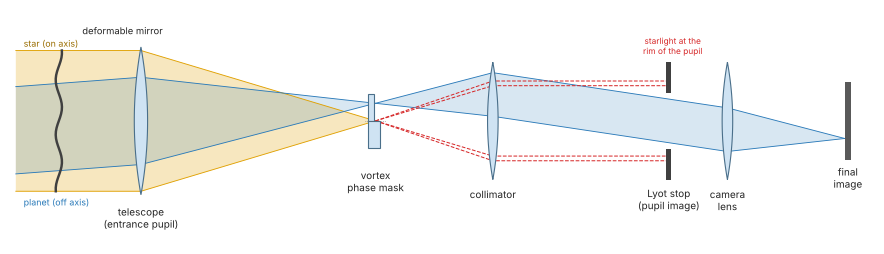

In [17]:
fig, ax = plt.subplots(figsize=(14, 4.4))
sketch.coronagraph_layout(ax, mask="vortex", dm=True)
plt.show()

In [18]:
# a smaller pupil (128 samples) for the dark hole: 848 actuators, a Jacobian of 848 propagations
xs = cg.pupil_grid(160, 1.25)
Xs, Ys = np.meshgrid(xs, xs)
Rs = np.hypot(Xs, Ys)
Ps = cg.telescope_pupil(xs, xs, oversample=16)
stop_s = cg.telescope_pupil(xs, xs, D=0.95, oversample=8)
v4 = cg.Coronagraph(xs, xs, Ps, "vortex", charge=4, lyot_stop=stop_s)

rng = np.random.default_rng(7)
K_phi, K_amp = 2.0e-5, 1.0e-6
phi = cg.aberration_screen(xs, xs, K_phi, 3.0, 1.0, rng)
amp = cg.aberration_screen(xs, xs, K_amp, 3.0, 1.0, rng)
wl = 550.0
print("phase error {:.2e} rad rms = {:.2f} nm rms wavefront at {:.0f} nm; amplitude error {:.2%} rms".format(
    phi[Rs < 0.5].std(), phi[Rs < 0.5].std()*wl/(2*np.pi), wl, amp[Rs < 0.5].std()))
E_ab = np.exp(amp + 1j*phi)

ud = cg.pupil_grid(128, 32)                         # +-16 lambda/D in 0.25 steps
UD, VD = np.meshgrid(ud, ud)
RD = np.hypot(UD, VD)
dark = (RD > 3) & (RD < 12) & (UD > 0.5)
I0 = v4.image(ud, ud, E_ab)
# speckle halo against the first order prediction (S_phi + S_amp)(u)/A_stop
A_stop = np.sum(stop_s)*(xs[1] - xs[0])**2
e_d = np.arange(3, 16, 1.0)
rc_d, p0 = cg.radial_profile(I0, ud, ud, e_d)
S = lambda f: (K_phi + K_amp)*(1 + f**2)**-1.5
print("\n  u (lambda/D)   speckles (ring mean)   (S_phi + S_amp)/A_stop")
for k in range(0, len(rc_d), 2):
    print("     {:4.1f}           {:.2e}               {:.2e}".format(rc_d[k], p0[k], S(rc_d[k])/A_stop))

phase error 1.13e-02 rad rms = 0.99 nm rms wavefront at 550 nm; amplitude error 0.20% rms



  u (lambda/D)   speckles (ring mean)   (S_phi + S_amp)/A_stop
      3.5           5.54e-07               6.14e-07
      5.5           1.69e-07               1.70e-07
      7.5           6.50e-08               6.84e-08
      9.5           3.15e-08               3.40e-08
     11.5           2.34e-08               1.93e-08
     13.5           1.36e-08               1.19e-08


One nanometre of wavefront error (about $\lambda/550$) and 0.2 %
amplitude ripple make speckles of $10^{-7}$ around 4 $\lambda/D$, a
thousand times brighter than an Earth twin. Their ring means follow the
first order prediction $S(u)/A$ within the scatter of a single random
screen (about 10 to 30 % per ring).

Now the deformable mirror: 32 × 32 actuators across the pupil, of which
848 lie on it, with Gaussian influence functions coupling 15 % to their
neighbours, controlling frequencies up to 16 $\lambda/D$. The Jacobian is
computed once with a coarser (faster) vortex model, and EFC runs eight
iterations on the true field, with a stronger regularization in the
first step.

In [19]:
H, act_xy = cg.dm_influence(xs, xs, 32, coupling=0.15)
v4_model = cg.Coronagraph(xs, xs, Ps, "vortex", charge=4, lyot_stop=stop_s,
                          scales=((0.25, 1/256), (2.0, 1/32), (32.0, 1/4)))
t0 = time.time()
G = cg.efc_jacobian(v4_model, E_ab, H, ud, ud, dark)
print("Jacobian: {} pixels x {} actuators, {:.0f} s".format(G.shape[0], G.shape[1], time.time() - t0))

cmd = np.zeros(len(H))
history = []
for it in range(9):
    E_dm = E_ab*np.exp(1j*np.tensordot(cmd, H, 1))
    F = v4.image_field(ud, ud, E_dm)
    history.append(np.mean(np.abs(F[dark])**2))
    if it < 8:
        cmd = cmd + cg.efc_step(G, F[dark], 1e-4 if it > 0 else 1e-3)
print("mean contrast in the dark hole per iteration: " + ", ".join("{:.1e}".format(h) for h in history))
dm_phase = np.tensordot(cmd, H, 1)
print("deformable mirror: {:.2f} nm rms wavefront (surface {:.2f} nm rms)".format(
    dm_phase[Rs < 0.5].std()*wl/(2*np.pi), dm_phase[Rs < 0.5].std()*wl/(4*np.pi)))
I1 = np.abs(F)**2

Jacobian: 3248 pixels x 848 actuators, 9 s


mean contrast in the dark hole per iteration: 1.0e-07, 1.3e-10, 1.3e-11, 7.2e-12, 5.9e-12, 5.2e-12, 4.7e-12, 4.3e-12, 4.0e-12
deformable mirror: 0.85 nm rms wavefront (surface 0.43 nm rms)


EFC digs the dark hole from $10^{-7}$ to a few $10^{-12}$ in a few
iterations; what remains is the part of the aberrations that 32
actuators cannot reach (frequencies above 16 $\lambda/D$ fold into the
hole) and the mismatch of the coarse Jacobian. The mirror shape is about
as large as the error, a nanometre.

Now a planet of $10^{-10}$ at $(6, 2)\,\lambda/D$, inside the dark hole. It is
incoherent with the star, so its image adds in intensity: the same
coronagraph, aberrations and mirror shape applied to a tilted wave.

planet peak: 7.96e-11 before, 7.95e-11 after correction (throughput 0.80)
residual starlight within 1-3 lambda/D of the planet after correction: mean 4.9e-12, max 3.7e-11
star in the planet's core region: 5.6e-08 before, 7.3e-12 after


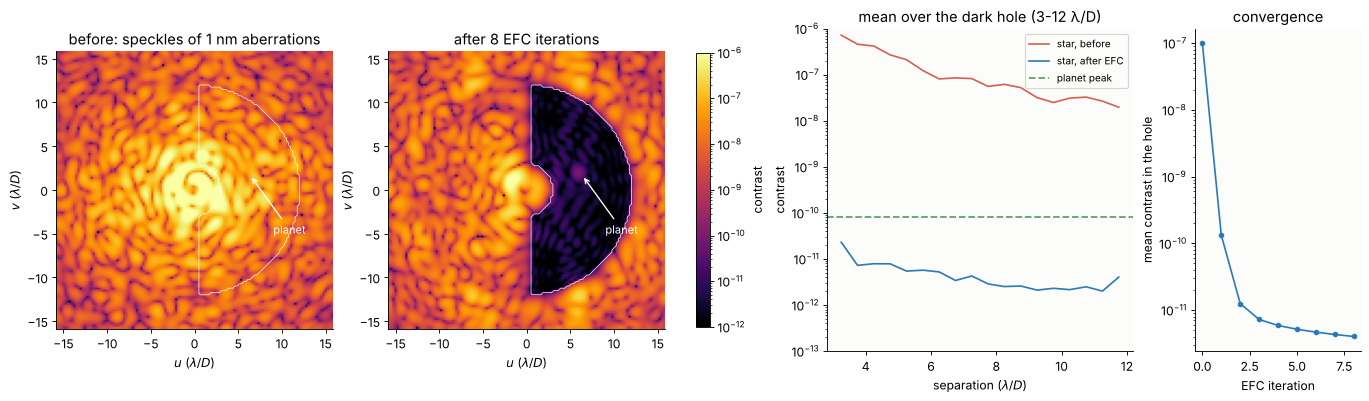

In [20]:
planet = (6.0, 2.0)
C_p = 1e-10
def planet_image(cmd):
    E = E_ab*np.exp(1j*np.tensordot(cmd, H, 1))*cg.tilt(xs, xs, *planet)
    return C_p*v4.image(ud, ud, E)
Ip0 = planet_image(np.zeros(len(H)))
Ip1 = planet_image(cmd)
print("planet peak: {:.2e} before, {:.2e} after correction (throughput {:.2f})".format(Ip0.max(), Ip1.max(),
                                                                                    Ip1.max()/C_p))
ring_p = (np.abs(np.hypot(UD - planet[0], VD - planet[1]) - 2.0) < 1.0) & dark
print("residual starlight within 1-3 lambda/D of the planet after correction: mean {:.1e}, max {:.1e}".format(
    I1[ring_p].mean(), I1[ring_p].max()))
core = np.hypot(UD - planet[0], VD - planet[1]) < 0.7
print("star in the planet's core region: {:.1e} before, {:.1e} after".format(I0[core].mean(), I1[core].mean()))

fig = plt.figure(figsize=(17, 4.9), layout="constrained")
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1.1, 0.6])
extd = [ud[0], ud[-1], ud[0], ud[-1]]
for k, (I, ttl) in enumerate(((I0 + Ip0, "before: speckles of 1 nm aberrations"),
                              (I1 + Ip1, "after 8 EFC iterations"))):
    a = fig.add_subplot(gs[k])
    im = a.imshow(I, extent=extd, origin="lower", norm=LogNorm(1e-12, 1e-6), cmap="inferno")
    a.contour(ud, ud, dark.astype(float), [0.5], colors="w", linewidths=0.6)
    a.annotate("planet", (planet[0] + 0.4, planet[1] - 0.4), (planet[0] + 3, planet[1] - 7), color="w",
               fontsize=10, arrowprops=dict(arrowstyle="->", color="w", lw=1.2))
    a.set_title(ttl); a.set_xlabel(r"$u$ ($\lambda/D$)"); a.set_ylabel(r"$v$ ($\lambda/D$)")
fig.colorbar(im, ax=fig.axes[:2], shrink=0.85, label="contrast")
a = fig.add_subplot(gs[2])
e_h = np.arange(2.5, 14, 0.5)
for I, col, lab in ((I0, RED, "before"), (I1, BLUE, "after EFC")):
    rch, ph = cg.radial_profile(I, ud, ud, e_h, mask=dark)
    a.semilogy(rch, ph, color=col, label="star, " + lab)
a.axhline(Ip1.max(), color=GREEN, lw=1.6, ls="--", label="planet peak")
a.set_ylim(1e-13, 1e-6); a.set_xlabel(r"separation ($\lambda/D$)"); a.set_ylabel("contrast")
a.legend(fontsize=9, loc="upper right"); a.set_title("mean over the dark hole (3-12 λ/D)")
a = fig.add_subplot(gs[3])
a.semilogy(np.arange(len(history)), history, "o-", color=BLUE, ms=4)
a.set_xlabel("EFC iteration"); a.set_ylabel("mean contrast in the hole"); a.set_title("convergence")
plt.show()

Before the correction, the planet is invisible under speckles a
thousand times brighter. After eight EFC iterations the right half of
the image is dark to a few $10^{-12}$, and the planet stands out at 16
times the mean residual starlight around it, with 80 % of its peak (the
charge 4 vortex at 6 $\lambda/D$). The
left half, which the mirror was not asked to correct, got brighter: the
mirror moved the speckles there.

Real instruments face what this monochromatic model leaves out: the
speckles change with wavelength (so a dark hole over a 10 to 20 % band
needs two deformable mirrors), the field must be estimated from noisy
images, and the telescope drifts during the hours of an exposure. The
Roman Space Telescope's coronagraph will demonstrate these techniques at
$10^{-8}$ to $10^{-9}$; a future Habitable Worlds Observatory needs $10^{-10}$.

## Summary

- An Earth twin is $2\times10^{-10}$ of its star at 5 $\lambda/D$ for a 6 m
  telescope at 550 nm; the Airy rings are at that level only 740 $\lambda/D$
  out (envelope $4/(\pi^4u^3)$).
- Apodization (Sonine, prolate) makes the PSF fall faster
  ($u^{-(2\nu+3)}$, checked against the analytic PSFs), at the cost of
  throughput and core width.
- The classical Lyot coronagraph leaves $J_0(\pi a)$ of the field inside
  the pupil (checked to $10^{-4}$ against the Hankel integral) and stalls
  at $10^{-5}$ near 5 $\lambda/D$.
- The APLC's prolate apodizer turns the Lyot plane field into $(1-\Lambda)A$
  (checked against the eigenvalue), and reaches $10^{-11}$ beyond its disk.
- The vortex moves all the light of a clear circular pupil outside it
  (the analytic Lyot fields of charge 2 and 4 are reproduced), with
  inner working angles of 1.2, 2.4 and 3.3 $\lambda/D$ for charge 2, 4, 6,
  but it leaks a central obscuration (checked against the analytic leak).
- Tip-tilt leaks as $\pi^2\alpha^2/8\,(D_L/D)^4$ for charge 2 and
  $\pi^4\alpha^4/192\,(D_L/D)^6$ for charge 4 (within 1 %), and a Zernike
  term passes a vortex only if $n + |m| \ge l$.
- One nanometre of aberrations makes speckles at $10^{-7}$ (following
  $S(u)/A$); a deformable mirror with electric field conjugation digs a
  half dark hole to a few $10^{-12}$, where a $10^{-10}$ planet is plain
  to see.

## References

- B. Lyot, "The study of the solar corona and prominences without
  eclipses", Mon. Not. R. Astron. Soc. 99, 580–594 (1939).
- W. B. Traub and B. R. Oppenheimer, "Direct imaging of exoplanets", in
  *Exoplanets*, ed. S. Seager, University of Arizona Press (2010), 111–156.
- C. Aime, R. Soummer and A. Ferrari, "Total coronagraphic extinction of
  rectangular apertures using linear prolate apodizations", Astron.
  Astrophys. 389, 334–344 (2002).
- R. Soummer, C. Aime and P. E. Falloon, "Stellar coronagraphy with
  prolate apodized circular apertures", Astron. Astrophys. 397,
  1161–1172 (2003).
- R. Soummer, L. Pueyo, A. Sivaramakrishnan and R. J. Vanderbei, "Fast
  computation of Lyot-style coronagraph propagation", Opt. Express 15,
  15935–15951 (2007).
- D. Mawet, P. Riaud, O. Absil and J. Surdej, "Annular groove phase mask
  coronagraph", Astrophys. J. 633, 1191–1200 (2005).
- G. Foo, D. M. Palacios and G. A. Swartzlander, "Optical vortex
  coronagraph", Opt. Lett. 30, 3308–3310 (2005).
- J. E. Krist, J. T. Trauger, E. Serabyn and D. Mawet, "Numerical modeling
  of the vortex coronagraph", Proc. SPIE 8151, 81510E (2011).
- G. Ruane, D. Mawet, B. Mennesson, J. Jewell and S. Shaklan, "Vortex
  coronagraphs for the Habitable Exoplanet Imaging Mission concept:
  theoretical performance and telescope requirements", J. Astron. Telesc.
  Instrum. Syst. 4, 015004 (2018).
- A. Give'on, R. Belikov, S. Shaklan and J. Kasdin, "Closed loop, DM
  diversity-based, wavefront correction algorithm for high contrast
  imaging systems", Opt. Express 15, 12338–12343 (2007).
- O. Guyon, E. A. Pluzhnik, M. J. Kuchner, B. Collins and S. T. Ridgway,
  "Theoretical limits on extrasolar terrestrial planet detection with
  coronagraphs", Astrophys. J. Suppl. 167, 81–99 (2006).

In [21]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 93 s
